# Tarea: Algoritmos Genéticos I

**Curso:** Diseño de algoritmos matemáticos bioinspirados
**Profesor:** Fernando Elizalde Ramírez

Contenido:
1. Balance de carga y minimización de comunicación (bisección con restricción de balance).
2. *Scheduling* de exámenes (coloración de grafos de conflictos).
3. Marketing dirigido (coloración del grafo de clientes).

En los tres casos se usa un algoritmo genético (AG). Para el caso 1 la solución del AG se contrasta
con el óptimo exacto del modelo lineal entero (HiGHS vía `scipy.optimize.milp`); para los casos 2 y 3
se reporta la cota inferior dada por la clique máxima $\omega(G) \le \chi(G)$.

In [1]:
import time, itertools, random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds

IMG = Path('Images'); IMG.mkdir(exist_ok=True)
RES = Path('resultados'); RES.mkdir(exist_ok=True)

AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'font.size': 10})
SEMILLA = 2026

## 1. Balance de carga y minimización de comunicación

### 1.1 Datos
El archivo contiene la carga computacional de las 30 tareas y una lista de pares (origen, destino, volumen MB/s).
Como la comunicación cruzada no depende de la dirección, los pares repetidos en ambos sentidos se suman en
una matriz simétrica $W$.

In [2]:
raw = pd.read_excel('sistema_balance_carga_30_tareas.xlsx', header=None)
cargas = raw.iloc[4:, [0, 1]].dropna()
cargas.columns = ['Tarea', 'Carga']
cargas['Carga'] = cargas['Carga'].astype(int)
com = raw.iloc[4:, [3, 4, 5]].dropna()
com.columns = ['Origen', 'Destino', 'Volumen']
com['Volumen'] = com['Volumen'].astype(int)

tareas = cargas['Tarea'].tolist()
idx = {t: i for i, t in enumerate(tareas)}
c = cargas['Carga'].to_numpy()
n1 = len(tareas)

W = np.zeros((n1, n1))
for o, d, v in com.itertuples(index=False):
    i, j = idx[o], idx[d]
    W[i, j] += v
    W[j, i] += v
aristas = [(i, j, W[i, j]) for i in range(n1) for j in range(i + 1, n1) if W[i, j] > 0]

C_total = c.sum()
print(f'Tareas: {n1} | carga total: {C_total} | filas de comunicación: {len(com)} '
      f'| pares no dirigidos: {len(aristas)} | volumen total: {W.sum() / 2:.0f} MB/s')

Tareas: 30 | carga total: 480 | filas de comunicación: 261 | pares no dirigidos: 261 | volumen total: 13863 MB/s


### 1.2 Modelo matemático

Sea $x_i = 1$ si la tarea $i$ se asigna al clúster A y $x_i = 0$ si va al clúster B; $c_i$ su carga y
$w_{ij}$ el volumen de comunicación entre $i$ y $j$. Con $C=\sum_i c_i$:

$$\min \; Z = \sum_{(i,j)\in E} w_{ij}\, y_{ij}$$
sujeto a
$$y_{ij} \ge x_i - x_j,\qquad y_{ij} \ge x_j - x_i \qquad \forall (i,j)\in E$$
$$\Big|\, \underbrace{\textstyle\sum_i c_i x_i}_{L_A} - \underbrace{\textstyle\sum_i c_i (1-x_i)}_{L_B} \Big| \le \delta\,\frac{C}{2},\qquad \delta = 0.10$$
$$x_i \in\{0,1\},\; y_{ij}\in[0,1].$$

La diferencia se mide respecto a la carga ideal por clúster $C/2$ (criterio más estricto que medirla respecto
al clúster más cargado). Como $L_A - L_B = 2\sum_i c_i x_i - C$, la restricción es lineal:
$C - \delta C/2 \le 2\sum_i c_i x_i \le C + \delta C/2$. Se fija $x_1 = 1$ para romper la simetría $x \leftrightarrow 1-x$.

In [3]:
DELTA = 0.10
D_MAX = DELTA * C_total / 2          # diferencia absoluta máxima permitida

def evaluar_particion(x):
    LA = int(c @ x); LB = int(C_total - LA)
    corte = float(x @ W @ (1 - x))   # suma w_ij con i en A y j en B
    return LA, LB, corte

def solucion_exacta():
    m = len(aristas)
    nv = n1 + m
    obj = np.concatenate([np.zeros(n1), [w for _, _, w in aristas]])
    A = np.zeros((2 * m + 1, nv)); lb = np.full(2 * m + 1, -np.inf); ub = np.zeros(2 * m + 1)
    for k, (i, j, _) in enumerate(aristas):
        A[2 * k, [i, j, n1 + k]] = [1, -1, -1]        # x_i - x_j - y <= 0
        A[2 * k + 1, [i, j, n1 + k]] = [-1, 1, -1]    # x_j - x_i - y <= 0
    A[-1, :n1] = 2 * c
    lb[-1], ub[-1] = C_total - D_MAX, C_total + D_MAX
    lo = np.zeros(nv); hi = np.ones(nv); lo[0] = 1                # x_1 = 1
    integ = np.concatenate([np.ones(n1), np.zeros(m)])
    t0 = time.perf_counter()
    r = milp(obj, constraints=LinearConstraint(A, lb, ub), integrality=integ,
             bounds=Bounds(lo, hi), options={'time_limit': 120})
    return np.round(r.x[:n1]).astype(int), r.fun, time.perf_counter() - t0, r.message

x_opt, z_opt, t_opt, msg = solucion_exacta()
print(msg)
print(f'Óptimo MILP: comunicación cruzada = {z_opt:.0f} MB/s en {t_opt:.2f} s; cargas = {evaluar_particion(x_opt)[:2]}')

Optimization terminated successfully. (HiGHS Status 7: Optimal)
Óptimo MILP: comunicación cruzada = 5335 MB/s en 17.36 s; cargas = (236, 244)


### 1.3 Algoritmo genético

* **Codificación:** vector binario de 30 genes ($x_i$).
* **Aptitud (a minimizar):** $f(x) = Z(x) + P\cdot\max\{0,\;|L_A-L_B| - \delta C/2\}$, con penalización $P$ grande
  para que cualquier solución balanceada domine a una no balanceada.
* **Selección:** torneo de tamaño 3. **Cruza:** uniforme ($p_c=0.9$). **Mutación:** inversión de bit con
  $p_m = 1/n$ por gen y, con probabilidad 0.3, intercambio de una tarea entre clústeres (ayuda a mantener el balance).
* **Elitismo:** se conservan los 2 mejores. Población 120, 300 generaciones.

In [4]:
P_PEN = W.sum()   # penalización por unidad de carga fuera de tolerancia

def aptitud_bis(X):
    LA = X @ c
    exceso = np.maximum(0, np.abs(2 * LA - C_total) - D_MAX)
    corte = np.einsum('pi,ij,pj->p', X, W, 1 - X)
    return corte + P_PEN * exceso

def torneo(fit, k, rng):
    cand = rng.integers(0, len(fit), size=k)
    return cand[np.argmin(fit[cand])]

def ag_biseccion(pop=120, gens=300, pc=0.9, pm=None, elite=2, semilla=0):
    rng = np.random.default_rng(semilla)
    pm = pm or 1 / n1
    X = rng.integers(0, 2, size=(pop, n1))
    fit = aptitud_bis(X)
    historia = [fit.min()]
    for g in range(gens):
        orden = np.argsort(fit)
        nuevos = [X[i].copy() for i in orden[:elite]]
        while len(nuevos) < pop:
            p1, p2 = X[torneo(fit, 3, rng)], X[torneo(fit, 3, rng)]
            hijo = np.where(rng.random(n1) < 0.5, p1, p2) if rng.random() < pc else p1.copy()
            flip = rng.random(n1) < pm
            hijo[flip] = 1 - hijo[flip]
            if rng.random() < 0.3:                      # intercambio A<->B
                a, b = np.flatnonzero(hijo == 1), np.flatnonzero(hijo == 0)
                if len(a) and len(b):
                    hijo[rng.choice(a)], hijo[rng.choice(b)] = 0, 1
            nuevos.append(hijo)
        X = np.array(nuevos)
        fit = aptitud_bis(X)
        historia.append(fit.min())
    b = np.argmin(fit)
    x = X[b] if X[b, 0] == 1 else 1 - X[b]           # misma convención que el MILP
    return x, fit[b], historia

corridas = []
for s in range(10):
    t0 = time.perf_counter()
    x, f, hist = ag_biseccion(semilla=SEMILLA + s)
    LA, LB, corte = evaluar_particion(x)
    corridas.append({'Corrida': s + 1, 'Tiempo (s)': time.perf_counter() - t0, 'Comunicación cruzada': corte,
                     'L_A': LA, 'L_B': LB, 'Dif. %': abs(LA - LB) / (C_total / 2) * 100,
                     'x': x, 'hist': hist})
df_bis = pd.DataFrame(corridas)
print(df_bis.drop(columns=['x', 'hist']).round(3).to_string(index=False))
print(f"\nPromedio: {df_bis['Comunicación cruzada'].mean():.1f} MB/s | mejor: {df_bis['Comunicación cruzada'].min():.0f} "
      f"| óptimo MILP: {z_opt:.0f} | corridas que alcanzan el óptimo: {(df_bis['Comunicación cruzada'] <= z_opt + 1e-6).sum()}/10")

 Corrida  Tiempo (s)  Comunicación cruzada  L_A  L_B  Dif. %
       1       0.620                5335.0  236  244   3.333
       2       0.637                5581.0  252  228  10.000
       3       0.611                5442.0  233  247   5.833
       4       0.610                5335.0  236  244   3.333
       5       0.609                5335.0  236  244   3.333
       6       0.609                5370.0  245  235   4.167
       7       0.631                5345.0  239  241   0.833
       8       0.607                5439.0  239  241   0.833
       9       0.609                5345.0  239  241   0.833
      10       0.615                5335.0  236  244   3.333

Promedio: 5386.2 MB/s | mejor: 5335 | óptimo MILP: 5335 | corridas que alcanzan el óptimo: 4/10


In [5]:
mejor = df_bis.loc[df_bis['Comunicación cruzada'].idxmin()]
x_ag = mejor['x']
LA, LB, corte = evaluar_particion(x_ag)

print('=== Distribución propuesta (mejor corrida del AG) ===')
for nombre, val in (('Clúster A', 1), ('Clúster B', 0)):
    sel = cargas[x_ag == val]
    print(f"{nombre} ({len(sel)} tareas, carga {sel['Carga'].sum()}):")
    print('   ' + ', '.join(f'{t}({w})' for t, w in sel.itertuples(index=False)))
print(f'\nDiferencia de carga: |{LA} - {LB}| = {abs(LA - LB)}  ->  '
      f'{abs(LA - LB) / (C_total / 2) * 100:.2f} % de la carga ideal ({C_total / 2:.1f}); '
      f'{abs(LA - LB) / max(LA, LB) * 100:.2f} % del clúster más cargado')
print(f'Comunicación cruzada: {corte:.0f} MB/s de {W.sum() / 2:.0f} MB/s totales '
      f'({corte / (W.sum() / 2) * 100:.1f} %)')
print(f'¿Coincide con el óptimo MILP? {np.isclose(corte, z_opt)}')

tabla = cargas.assign(Cluster=np.where(x_ag == 1, 'A', 'B'))
tabla.to_csv(RES / 'balance_asignacion.csv', index=False)

# aristas que cruzan el corte
cruz = [(tareas[i], tareas[j], int(w)) for i, j, w in aristas if x_ag[i] != x_ag[j]]
print(f'\nPares que se comunican entre clústeres ({len(cruz)}):')
print(sorted(cruz, key=lambda t: -t[2]))

=== Distribución propuesta (mejor corrida del AG) ===
Clúster A (14 tareas, carga 236):
   T01(14), T02(22), T03(18), T05(14), T06(18), T15(8), T18(24), T19(17), T21(22), T22(22), T23(19), T24(10), T26(14), T28(14)
Clúster B (16 tareas, carga 244):
   T04(15), T07(18), T08(11), T09(15), T10(10), T11(9), T12(19), T13(13), T14(9), T16(19), T17(19), T20(23), T25(12), T27(16), T29(25), T30(11)

Diferencia de carga: |236 - 244| = 8  ->  3.33 % de la carga ideal (240.0); 3.28 % del clúster más cargado
Comunicación cruzada: 5335 MB/s de 13863 MB/s totales (38.5 %)
¿Coincide con el óptimo MILP? True

Pares que se comunican entre clústeres (118):
[('T06', 'T27', 96), ('T10', 'T24', 96), ('T15', 'T30', 96), ('T02', 'T07', 95), ('T12', 'T28', 95), ('T13', 'T24', 95), ('T10', 'T28', 92), ('T01', 'T27', 89), ('T24', 'T27', 89), ('T16', 'T26', 87), ('T01', 'T30', 84), ('T08', 'T22', 81), ('T01', 'T04', 80), ('T05', 'T13', 79), ('T08', 'T23', 79), ('T20', 'T21', 77), ('T05', 'T10', 76), ('T15', 'T20'

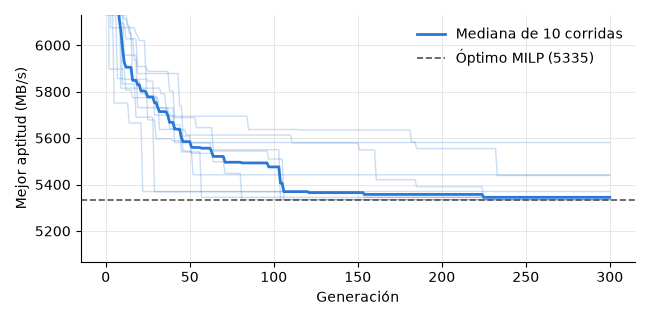

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
h = np.array([r for r in df_bis['hist']])
gens = np.arange(h.shape[1])
for r in h:
    ax.plot(gens, r, color=AZUL, alpha=0.25, lw=1)
ax.plot(gens, np.median(h, axis=0), color=AZUL, lw=2, label='Mediana de 10 corridas')
ax.axhline(z_opt, color=GRIS, ls='--', lw=1.2, label=f'Óptimo MILP ({z_opt:.0f})')
ax.set_ylim(z_opt * 0.95, np.percentile(h[:, 5:], 99))
ax.set_xlabel('Generación'); ax.set_ylabel('Mejor aptitud (MB/s)')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(IMG / 'balance_convergencia.pdf'); plt.show()

## 2. *Scheduling* de exámenes

Cada curso es un vértice y existe una arista cuando dos cursos comparten estudiantes. Una asignación de horarios
sin traslapes es una coloración propia; el número de horas es el número de colores $k$, que se desea minimizar
($\chi(G)$).

### 2.1 Algoritmo genético
* **Codificación:** permutación de los cursos.
* **Decodificador:** coloración voraz en el orden de la permutación (cada curso toma la primera hora libre
  respecto a sus vecinos). Toda permutación produce un horario **factible** (0 conflictos), y existe al menos un
  orden que produce una coloración óptima, por lo que el espacio de búsqueda contiene al óptimo.
* **Aptitud (a minimizar):** $f = k + s_{\min}/(n+1)$, donde $s_{\min}$ es el tamaño de la hora con menos exámenes;
  el segundo término desempata y empuja a vaciar la hora más pequeña.
* **Operadores:** torneo (3), cruza de orden OX ($p_c=0.9$), mutación por intercambio e inserción ($p_m=0.3$), elitismo 2.
* **Parámetros:** población 80, 250 generaciones (presupuesto fijo para comparar tiempos entre tamaños).
* **Calidad:** número de horas $k$ y brecha respecto al número cromático exacto $\chi(G)$: $(k-\chi)/\chi$.
  $\chi(G)$ se certifica con un modelo entero de factibilidad: se resuelve para $k=\omega,\omega+1,\dots$ hasta
  encontrar el primer $k$ factible (los anteriores son infactibles, lo que prueba la optimalidad).

In [7]:
def leer_grafo(df):
    G = nx.Graph()
    for fila in df.itertuples(index=False):
        u = fila[0]
        G.add_node(u)
        for v in fila[1:]:
            if isinstance(v, str):
                G.add_edge(u, v)
    return G

hojas = pd.read_excel('grafos_de_conflictos-1.xlsx', sheet_name=None)
grafos = {nombre: leer_grafo(df) for nombre, df in hojas.items()}

info = []
for nombre, G in grafos.items():
    omega = max(len(q) for q in nx.find_cliques(G))
    dsatur = max(nx.greedy_color(G, strategy='DSATUR').values()) + 1
    info.append({'Caso': nombre, 'n': G.number_of_nodes(), 'm': G.number_of_edges(),
                 'Densidad': nx.density(G), 'Grado máx.': max(d for _, d in G.degree()),
                 'ω (cota inf.)': omega, 'DSatur': dsatur})
df_info = pd.DataFrame(info)

def k_coloreable(G, k):
    # Modelo de factibilidad: sum_c z_vc = 1;  z_uc + z_vc <= 1 para cada arista y color.
    from scipy.sparse import lil_matrix
    nod = list(G); p = {v: i for i, v in enumerate(nod)}; n = len(nod); E = list(G.edges())
    A = lil_matrix((n + len(E) * k, n * k)); lb, ub = [], []
    for i in range(n):
        A[i, i * k:(i + 1) * k] = 1; lb.append(1); ub.append(1)
    r = n
    for u, v in E:
        for col in range(k):
            A[r, p[u] * k + col] = 1; A[r, p[v] * k + col] = 1; lb.append(0); ub.append(1); r += 1
    lo, hi = np.zeros(n * k), np.ones(n * k)
    for col, v in enumerate(max(nx.find_cliques(G), key=len)[:k]):   # fija la clique máxima (simetría)
        lo[p[v] * k + col] = 1
    res = milp(np.zeros(n * k), constraints=LinearConstraint(A.tocsr(), lb, ub),
               integrality=np.ones(n * k), bounds=Bounds(lo, hi), options={'time_limit': 300})
    return res.status == 0

chis, t_chi = [], []
for nombre, G in grafos.items():
    t0 = time.perf_counter()
    k = df_info.set_index('Caso').loc[nombre, 'ω (cota inf.)']
    while not k_coloreable(G, k):
        k += 1
    chis.append(k); t_chi.append(time.perf_counter() - t0)
df_info['χ (exacto)'] = chis
df_info['Tiempo χ (s)'] = t_chi
print(df_info.round(3).to_string(index=False))

     Caso   n   m  Densidad  Grado máx.  ω (cota inf.)  DSatur  χ (exacto)  Tiempo χ (s)
 Grafo_20  20 130     0.684          16              7       8           8         0.016
 Grafo_30  30 172     0.395          18              5       7           6         0.015
 Grafo_50  50 317     0.259          19              5       7           6         0.026
 Grafo_75  75 485     0.175          19              4       6           6         3.094
Grafo_100 100 626     0.126          22              4       6           6        48.916


In [8]:
class AGColoracion:
    # AG con codificación por permutación y decodificador voraz.
    def __init__(self, G, pop=80, gens=250, pc=0.9, pm=0.3, elite=2, semilla=0):
        self.nodos = list(G.nodes())
        pos = {v: i for i, v in enumerate(self.nodos)}
        self.ady = [[pos[u] for u in G[v]] for v in self.nodos]
        self.n = len(self.nodos)
        self.pop, self.gens, self.pc, self.pm, self.elite = pop, gens, pc, pm, elite
        self.rng = random.Random(semilla)

    def decodificar(self, perm):
        color = [-1] * self.n
        for v in perm:
            usados = {color[u] for u in self.ady[v]}
            k = 0
            while k in usados:
                k += 1
            color[v] = k
        return color

    def aptitud(self, perm):
        color = self.decodificar(perm)
        tam = Counter(color)
        return len(tam) + min(tam.values()) / (self.n + 1)

    def ox(self, p1, p2):
        a, b = sorted(self.rng.sample(range(self.n), 2))
        hijo = [None] * self.n
        hijo[a:b] = p1[a:b]
        tomados = set(p1[a:b])
        resto = [g for g in p2 if g not in tomados]
        j = 0
        for i in range(self.n):
            if hijo[i] is None:
                hijo[i] = resto[j]; j += 1
        return hijo

    def mutar(self, p):
        i, j = self.rng.sample(range(self.n), 2)
        if self.rng.random() < 0.5:
            p[i], p[j] = p[j], p[i]
        else:
            p.insert(j, p.pop(i))

    def torneo(self, P, F):
        cand = self.rng.sample(range(len(P)), 3)
        return P[min(cand, key=lambda i: F[i])]

    def resolver(self):
        P = [self.rng.sample(range(self.n), self.n) for _ in range(self.pop)]
        F = [self.aptitud(p) for p in P]
        self.historia = [min(F)]
        for _ in range(self.gens):
            orden = sorted(range(self.pop), key=lambda i: F[i])
            nuevos = [P[i][:] for i in orden[:self.elite]]
            while len(nuevos) < self.pop:
                p1, p2 = self.torneo(P, F), self.torneo(P, F)
                h = self.ox(p1, p2) if self.rng.random() < self.pc else p1[:]
                if self.rng.random() < self.pm:
                    self.mutar(h)
                nuevos.append(h)
            P = nuevos
            F = [self.aptitud(p) for p in P]
            self.historia.append(min(F))
        b = min(range(self.pop), key=lambda i: F[i])
        color = self.decodificar(P[b])
        return {self.nodos[i]: color[i] for i in range(self.n)}

def conflictos(G, asig):
    return sum(asig[u] == asig[v] for u, v in G.edges())

In [9]:
REPS = 5
registros, mejores, historias = [], {}, {}
for nombre, G in grafos.items():
    chi = df_info.set_index('Caso').loc[nombre, 'χ (exacto)']
    for r in range(REPS):
        ag = AGColoracion(G, semilla=SEMILLA + r)
        t0 = time.perf_counter()
        asig = ag.resolver()
        t = time.perf_counter() - t0
        k = max(asig.values()) + 1
        registros.append({'Caso': nombre, 'n': G.number_of_nodes(), 'Corrida': r + 1, 'Tiempo (s)': t,
                          'Horas (k)': k, 'Conflictos': conflictos(G, asig), 'Brecha %': (k - chi) / chi * 100, 'Óptimo': k == chi})
        historias.setdefault(nombre, []).append(ag.historia)
        if nombre not in mejores or k < max(mejores[nombre].values()) + 1:
            mejores[nombre] = asig
df_runs = pd.DataFrame(registros)
df_runs.to_csv(RES / 'scheduling_corridas.csv', index=False)
print(df_runs.round(3).to_string(index=False))

     Caso   n  Corrida  Tiempo (s)  Horas (k)  Conflictos  Brecha %  Óptimo
 Grafo_20  20        1       0.353          8           0       0.0    True
 Grafo_20  20        2       0.353          8           0       0.0    True
 Grafo_20  20        3       0.378          8           0       0.0    True
 Grafo_20  20        4       0.354          8           0       0.0    True
 Grafo_20  20        5       0.357          8           0       0.0    True
 Grafo_30  30        1       0.430          6           0       0.0    True
 Grafo_30  30        2       0.428          6           0       0.0    True
 Grafo_30  30        3       0.430          6           0       0.0    True
 Grafo_30  30        4       0.430          6           0       0.0    True
 Grafo_30  30        5       0.426          6           0       0.0    True
 Grafo_50  50        1       0.671          6           0       0.0    True
 Grafo_50  50        2       0.658          6           0       0.0    True
 Grafo_50  5

In [10]:
resumen = (df_runs.groupby('n')
           .agg(**{'Tiempo prom. (s)': ('Tiempo (s)', 'mean'), 'Tiempo desv. (s)': ('Tiempo (s)', 'std'),
                   'Horas prom.': ('Horas (k)', 'mean'), 'Mejor k': ('Horas (k)', 'min'),
                   'Peor k': ('Horas (k)', 'max'), 'Conflictos prom.': ('Conflictos', 'mean'),
                   'Brecha prom. %': ('Brecha %', 'mean'),
                   'Corridas óptimas': ('Óptimo', 'sum')})
           .reset_index())
resumen = resumen.merge(df_info[['n', 'm', 'ω (cota inf.)', 'χ (exacto)', 'DSatur']], on='n')
resumen.to_csv(RES / 'scheduling_resumen.csv', index=False)
print(resumen.round(3).to_string(index=False))

  n  Tiempo prom. (s)  Tiempo desv. (s)  Horas prom.  Mejor k  Peor k  Conflictos prom.  Brecha prom. %  Corridas óptimas   m  ω (cota inf.)  χ (exacto)  DSatur
 20             0.359             0.011          8.0        8       8               0.0             0.0                 5 130              7           8       8
 30             0.429             0.002          6.0        6       6               0.0             0.0                 5 172              5           6       7
 50             0.667             0.005          6.0        6       6               0.0             0.0                 5 317              5           6       7
 75             0.949             0.008          6.0        6       6               0.0             0.0                 5 485              4           6       6
100             1.200             0.027          6.0        6       6               0.0             0.0                 5 626              4           6       6


In [11]:
print('=== Distribución de exámenes por hora (mejor solución de cada caso) ===')
filas = []
for nombre, asig in mejores.items():
    k = max(asig.values()) + 1
    print(f'\n{nombre}: {k} horas, conflictos = {conflictos(grafos[nombre], asig)}')
    for h in range(k):
        cursos = sorted([v for v, col in asig.items() if col == h], key=lambda s: int(s[1:]))
        print(f'  Hora {h + 1:>2} ({len(cursos):>2}): ' + ', '.join(cursos))
        filas.append({'Caso': nombre, 'Hora': h + 1, 'Num. exámenes': len(cursos), 'Cursos': ', '.join(cursos)})
pd.DataFrame(filas).to_csv(RES / 'scheduling_horarios.csv', index=False)

=== Distribución de exámenes por hora (mejor solución de cada caso) ===

Grafo_20: 8 horas, conflictos = 0
  Hora  1 ( 4): C1, C4, C8, C15
  Hora  2 ( 3): C7, C10, C12
  Hora  3 ( 2): C14, C20
  Hora  4 ( 3): C5, C9, C17
  Hora  5 ( 3): C2, C3, C13
  Hora  6 ( 2): C6, C18
  Hora  7 ( 2): C16, C19
  Hora  8 ( 1): C11

Grafo_30: 6 horas, conflictos = 0
  Hora  1 ( 8): C1, C3, C6, C9, C22, C24, C28, C29
  Hora  2 ( 6): C4, C8, C10, C13, C18, C27
  Hora  3 ( 4): C17, C20, C25, C30
  Hora  4 ( 5): C7, C12, C15, C19, C26
  Hora  5 ( 5): C2, C5, C14, C16, C23
  Hora  6 ( 2): C11, C21

Grafo_50: 6 horas, conflictos = 0
  Hora  1 (10): C6, C7, C8, C9, C20, C23, C31, C38, C46, C50
  Hora  2 (10): C14, C15, C16, C24, C25, C30, C33, C37, C39, C41
  Hora  3 (10): C2, C12, C17, C18, C26, C28, C35, C45, C48, C49
  Hora  4 ( 9): C3, C5, C13, C19, C21, C22, C36, C43, C44
  Hora  5 ( 8): C1, C4, C10, C11, C27, C29, C34, C40
  Hora  6 ( 3): C32, C42, C47

Grafo_75: 6 horas, conflictos = 0
  Hora  1 (16):

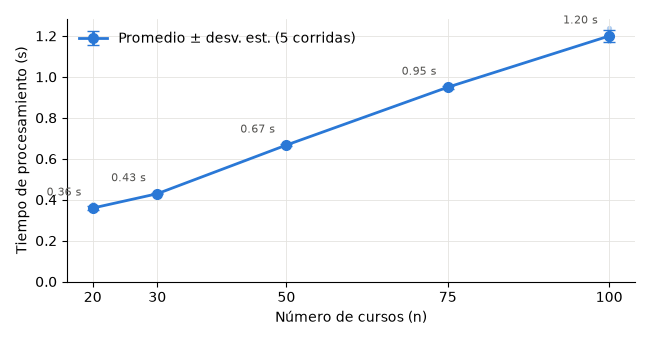

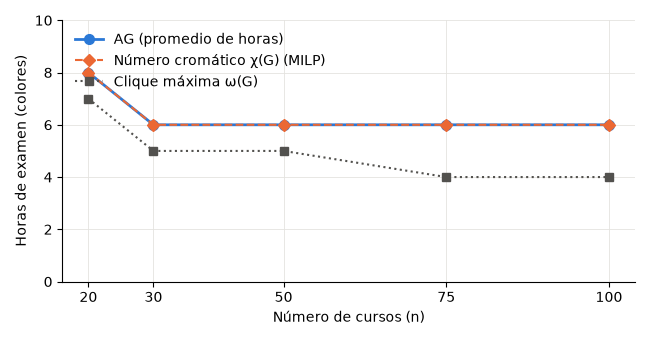

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for n_, g in df_runs.groupby('n'):
    ax.scatter(np.full(len(g), n_), g['Tiempo (s)'], s=14, color=AZUL, alpha=0.35, lw=0)
ax.errorbar(resumen['n'], resumen['Tiempo prom. (s)'], yerr=resumen['Tiempo desv. (s)'],
            color=AZUL, lw=2, marker='o', ms=7, capsize=4, label='Promedio ± desv. est. (5 corridas)')
for n_, t_ in zip(resumen['n'], resumen['Tiempo prom. (s)']):
    ax.annotate(f'{t_:.2f} s', (n_, t_), textcoords='offset points', xytext=(-8, 9), fontsize=8, color=GRIS, ha='right')
ax.set_xlabel('Número de cursos (n)'); ax.set_ylabel('Tiempo de procesamiento (s)')
ax.set_xticks(resumen['n']); ax.set_ylim(bottom=0)
ax.legend(frameon=False, loc='upper left')
fig.tight_layout(); fig.savefig(IMG / 'scheduling_tiempo.pdf'); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(resumen['n'], resumen['Horas prom.'], color=AZUL, lw=2, marker='o', ms=7, label='AG (promedio de horas)')
ax.plot(resumen['n'], resumen['χ (exacto)'], color=NARANJA, lw=1.5, ls='--', marker='D', ms=6, label='Número cromático χ(G) (MILP)')
ax.plot(resumen['n'], resumen['ω (cota inf.)'], color=GRIS, lw=1.5, ls=':', marker='s', ms=6, label='Clique máxima ω(G)')
ax.set_xlabel('Número de cursos (n)'); ax.set_ylabel('Horas de examen (colores)')
ax.set_xticks(resumen['n']); ax.set_ylim(0, resumen['Horas prom.'].max() + 2)
ax.legend(frameon=False, loc='upper left')
fig.tight_layout(); fig.savefig(IMG / 'scheduling_calidad.pdf'); plt.show()

## 3. Marketing dirigido

### 3.1 Análisis de preferencias

In [13]:
mk = pd.read_excel('marketing_50_clientes.xlsx')
mk['Prefs'] = mk['Preferencias'].str.split(',').apply(lambda l: frozenset(s.strip() for s in l))

frec = Counter(cat for p in mk['Prefs'] for cat in p)
df_frec = pd.DataFrame(frec.most_common(), columns=['Categoría', 'Clientes'])
df_frec['% clientes'] = df_frec['Clientes'] / len(mk) * 100
print(df_frec.round(1).to_string(index=False))

pares = Counter(par for p in mk['Prefs'] for par in itertools.combinations(sorted(p), 2))
print('\nPares de categorías más frecuentes (patrones de consumo):')
for par, f in pares.most_common(10):
    print(f'  {par[0]} + {par[1]}: {f} clientes')

tercias = Counter(tuple(sorted(p)) for p in mk['Prefs'])
print('\nCombinaciones completas repetidas:')
for t, f in tercias.most_common():
    if f > 1:
        clientes = mk.loc[mk['Prefs'].apply(lambda p: tuple(sorted(p)) == t), 'Cliente'].tolist()
        print(f"  {' + '.join(t)}: {f} clientes -> {', '.join(clientes)}")

   Categoría  Clientes  % clientes
      Travel        17        34.0
      Gaming        13        26.0
       Music        13        26.0
   Streaming        12        24.0
Gourmet Food        11        22.0
  Automotive        10        20.0
 Electronics         9        18.0
  Home Decor         9        18.0
     Fitness         9        18.0
        Kids         9        18.0
  Sportswear         9        18.0
      Beauty         8        16.0
        Pets         8        16.0
       Books         7        14.0
    Outdoors         6        12.0

Pares de categorías más frecuentes (patrones de consumo):
  Streaming + Travel: 5 clientes
  Home Decor + Travel: 5 clientes
  Gaming + Music: 4 clientes
  Automotive + Sportswear: 4 clientes
  Electronics + Gaming: 3 clientes
  Gourmet Food + Travel: 3 clientes
  Books + Travel: 3 clientes
  Music + Streaming: 3 clientes
  Gaming + Home Decor: 3 clientes
  Electronics + Travel: 3 clientes

Combinaciones completas repetidas:
  Electron

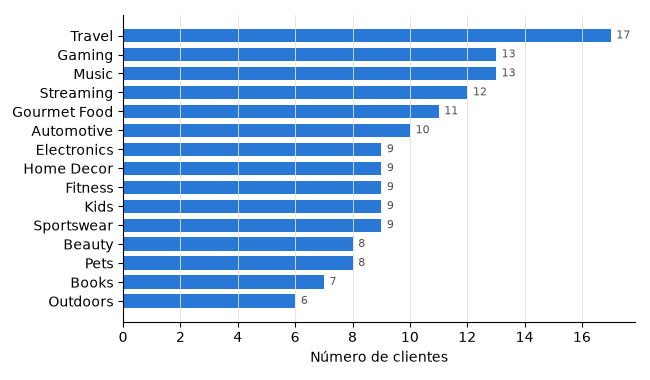

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
d = df_frec.iloc[::-1]
ax.barh(d['Categoría'], d['Clientes'], color=AZUL, height=0.7)
for y, v in enumerate(d['Clientes']):
    ax.text(v + 0.2, y, str(v), va='center', fontsize=8, color=GRIS)
ax.set_xlabel('Número de clientes'); ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(IMG / 'marketing_frecuencias.pdf'); plt.show()

### 3.2 Construcción del grafo de clientes
Dos clientes están en conflicto si comparten al menos 2 categorías. Se compara el grafo construido con la
columna *Conflictos con* del archivo.

In [15]:
Gm = nx.Graph()
Gm.add_nodes_from(mk['Cliente'])
pref = dict(zip(mk['Cliente'], mk['Prefs']))
for a, b in itertools.combinations(mk['Cliente'], 2):
    if len(pref[a] & pref[b]) >= 2:
        Gm.add_edge(a, b)

Gf = nx.Graph(); Gf.add_nodes_from(mk['Cliente'])
for cl, conf in zip(mk['Cliente'], mk['Conflictos con']):
    if isinstance(conf, str):
        Gf.add_edges_from((cl, o.strip()) for o in conf.split(','))
iguales = {frozenset(e) for e in Gm.edges()} == {frozenset(e) for e in Gf.edges()}
print(f'Aristas construidas: {Gm.number_of_edges()} | aristas del archivo: {Gf.number_of_edges()} | ¿iguales? {iguales}')

aislados = sorted(nx.isolates(Gm), key=lambda s: int(s[1:]))
comps = sorted(nx.connected_components(Gm), key=len, reverse=True)
omega_m = max(len(q) for q in nx.find_cliques(Gm))
clique_max = max(nx.find_cliques(Gm), key=len)
print(f'Densidad: {nx.density(Gm):.3f} | grado máx.: {max(d for _, d in Gm.degree())} | '
      f'componentes: {len(comps)} | aislados: {aislados}')
print(f'Clique máxima (ω = {omega_m}): {sorted(clique_max, key=lambda s: int(s[1:]))}')
print('Comunidades (componentes conexas con ≥ 2 clientes):')
for comp in comps:
    if len(comp) > 1:
        cats = Counter(cat for v in comp for cat in pref[v]).most_common(3)
        print(f"  {len(comp):>2} clientes: {', '.join(sorted(comp, key=lambda s: int(s[1:])))}"
              f"  | categorías dominantes: {', '.join(c for c, _ in cats)}")

Aristas construidas: 94 | aristas del archivo: 94 | ¿iguales? True
Densidad: 0.077 | grado máx.: 8 | componentes: 4 | aislados: ['C6', 'C21']
Clique máxima (ω = 5): ['C8', 'C9', 'C11', 'C40', 'C50']
Comunidades (componentes conexas con ≥ 2 clientes):
  46 clientes: C1, C2, C3, C4, C5, C7, C8, C9, C10, C11, C12, C13, C14, C15, C16, C18, C19, C20, C22, C23, C24, C25, C26, C27, C28, C29, C30, C31, C32, C33, C34, C35, C36, C37, C38, C39, C40, C42, C43, C44, C45, C46, C47, C48, C49, C50  | categorías dominantes: Travel, Music, Gaming
   2 clientes: C17, C41  | categorías dominantes: Pets, Sportswear, Music


### 3.3 Solución
Se reutiliza el AG de coloración: cada color es una campaña. Se ejecuta 5 veces.

In [16]:
res_mk = []
for r in range(5):
    ag = AGColoracion(Gm, semilla=SEMILLA + r)
    t0 = time.perf_counter(); asig = ag.resolver(); t = time.perf_counter() - t0
    res_mk.append((max(asig.values()) + 1, t, asig))
    print(f'Corrida {r + 1}: {res_mk[-1][0]} campañas, conflictos = {conflictos(Gm, asig)}, {t:.2f} s')
k_mk, _, asig_mk = min(res_mk, key=lambda z: z[0])
print(f'\nCampañas necesarias: {k_mk} (cota inferior ω = {omega_m} -> solución óptima: {k_mk == omega_m})')

nombres = [f'Campaña {chr(65 + i)}' for i in range(k_mk)]
mk['Campaña'] = mk['Cliente'].map(lambda cl: nombres[asig_mk[cl]])
for nm in nombres:
    g = mk[mk['Campaña'] == nm]
    top = Counter(cat for p in g['Prefs'] for cat in p).most_common(3)
    print(f"{nm} ({len(g)} clientes): {', '.join(g['Cliente'])}")
    print(f"   categorías más comunes: {', '.join(f'{c} ({v})' for c, v in top)}")
mk.drop(columns='Prefs').to_excel(RES / 'marketing_campanas.xlsx', index=False)

Corrida 1: 5 campañas, conflictos = 0, 0.44 s
Corrida 2: 5 campañas, conflictos = 0, 0.42 s
Corrida 3: 5 campañas, conflictos = 0, 0.43 s
Corrida 4: 5 campañas, conflictos = 0, 0.43 s
Corrida 5: 5 campañas, conflictos = 0, 0.44 s

Campañas necesarias: 5 (cota inferior ω = 5 -> solución óptima: True)
Campaña A (18 clientes): C1, C3, C6, C10, C11, C12, C14, C15, C17, C18, C19, C21, C23, C24, C39, C42, C45, C47
   categorías más comunes: Gaming (5), Music (5), Travel (5)
Campaña B (17 clientes): C5, C9, C13, C26, C27, C28, C30, C32, C33, C34, C35, C37, C38, C41, C44, C48, C49
   categorías más comunes: Travel (5), Music (5), Automotive (4)
Campaña C (9 clientes): C4, C16, C20, C22, C29, C31, C40, C43, C46
   categorías más comunes: Gaming (3), Streaming (3), Travel (3)
Campaña D (5 clientes): C2, C7, C8, C25, C36
   categorías más comunes: Travel (3), Gaming (2), Beauty (2)
Campaña E (1 clientes): C50
   categorías más comunes: Home Decor (1), Travel (1), Streaming (1)


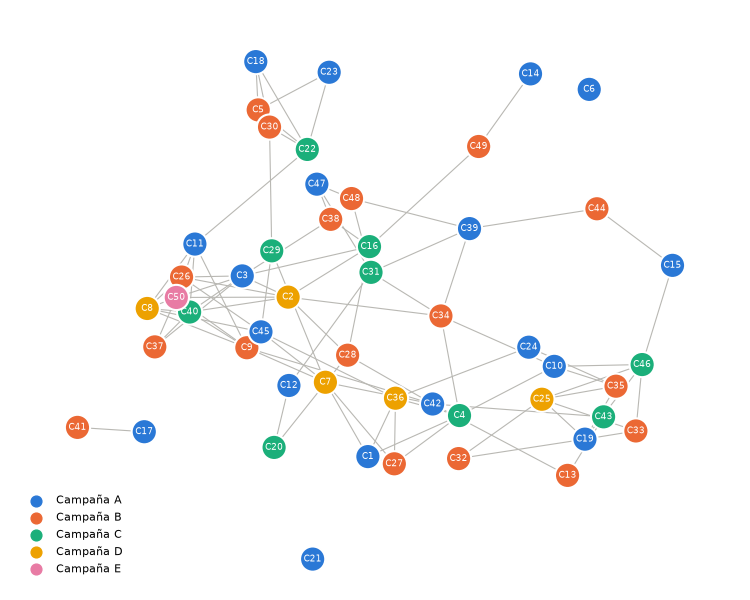

In [17]:
PALETA = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']
fig, ax = plt.subplots(figsize=(7.5, 6))
pos = nx.spring_layout(Gm, seed=7, k=0.45)
nx.draw_networkx_edges(Gm, pos, ax=ax, edge_color='#b9b8b3', width=0.8)
nx.draw_networkx_nodes(Gm, pos, ax=ax, node_size=330, edgecolors='white', linewidths=1.5,
                       node_color=[PALETA[asig_mk[v]] for v in Gm.nodes()])
nx.draw_networkx_labels(Gm, pos, ax=ax, font_size=6.5, font_color='white')
for i, nm in enumerate(nombres):
    ax.scatter([], [], color=PALETA[i], s=60, label=nm)
ax.legend(frameon=False, loc='lower left', fontsize=8)
ax.axis('off')
fig.tight_layout(); fig.savefig(IMG / 'marketing_grafo.pdf'); plt.show()